# Meeting 2 — Text-to-image generation

**Question:** which text-to-image generation settings give useful Egyptian Mau training images?

Each pool holds 110 images generated by Stable Diffusion 1.5 (`synth-generate`); each training seed adds a different
random 55 of them to the 15 real Egyptian Mau photos (`synth-train --method synthetic`). Everything else is as in
Meeting 1: EfficientNet-B0, 5 seeds, choices on the validation photos, the test photos only for the chosen run.

**Design:** one base pool, then pools that each change **one** setting of the base and keep all others:

| Pool | Setting changed | Value (base value) |
|---|---|---|
| `m2-base` | — | SD 1.5, 1 prompt, 30 steps, guidance 7.5, DPM scheduler, seed 1000 |
| `m2-guidance-2` | guidance | 2 (7.5) |
| `m2-guidance-15` | guidance | 15 (7.5) |
| `m2-steps-5` | steps | 5 (30) |
| `m2-steps-10` | steps | 10 (30) |
| `m2-prompts-varied` | prompt | 4 varied prompts (1 prompt) |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as ShowImage
from PIL import Image

from synthdata import generate, test, train
from synthdata.config import CLASSES, EVIDENCE_DIR, POOLS_DIR, RUNS_DIR, TARGET

pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 110)
EVIDENCE_DIR.mkdir(exist_ok=True)

BASELINES = ["m1-real", "m1-oversample", "m1-augment"]
POOLS = ["m2-base", "m2-guidance-2", "m2-guidance-15", "m2-steps-5", "m2-steps-10", "m2-prompts-varied"]

## 1. Prompts

**Base prompt** (also used by every pool except `m2-prompts-varied`):

> *a photo of an Egyptian Mau cat, silver coat with random dark spots, green eyes, at home*

It names what makes an Egyptian Mau an Egyptian Mau: a silver coat with **random dark spots** (not stripes, and not the
rosettes of a Bengal) and green eyes; "a photo … at home" asks for ordinary pet photos like those in Oxford-IIIT Pet.
The negative prompt is the repository's default (*illustration, painting, cartoon, text, watermark, multiple cats,
deformed animal, extra limbs*).

**Varied prompts** (`m2-prompts-varied`, used in turn): the same breed description, but different scenes, poses and the
second official coat colour, bronze:

1. *a photo of an Egyptian Mau cat lying on a sofa, silver coat with random dark spots, green eyes*
2. *a photo of an Egyptian Mau cat sitting in a garden, bronze coat with random dark spots, green eyes*
3. *a full-body photo of an Egyptian Mau cat walking on the floor, silver coat with random dark spots*
4. *a photo of an Egyptian Mau cat playing with a toy indoors, bronze coat with random dark spots*

## 2. Generating the pools

The same commands as in the terminal. A pool is generated only if it does not exist yet: the images are not committed,
so on another computer the cell does **not** regenerate them (the manifests and contact sheets are in Git).

```bash
uv run synth-generate --name m2-base --prompt "<base prompt>"
uv run synth-generate --name m2-guidance-2 --prompt "<base prompt>" --guidance 2
uv run synth-generate --name m2-guidance-15 --prompt "<base prompt>" --guidance 15
uv run synth-generate --name m2-steps-5 --prompt "<base prompt>" --steps 5
uv run synth-generate --name m2-steps-10 --prompt "<base prompt>" --steps 10
uv run synth-generate --name m2-prompts-varied --prompt "<varied 1>" --prompt "<varied 2>" --prompt "<varied 3>" --prompt "<varied 4>"
```

In [2]:
PROMPT = 'a photo of an Egyptian Mau cat, silver coat with random dark spots, green eyes, at home'
VARIED = ['a photo of an Egyptian Mau cat lying on a sofa, silver coat with random dark spots, green eyes', 'a photo of an Egyptian Mau cat sitting in a garden, bronze coat with random dark spots, green eyes', 'a full-body photo of an Egyptian Mau cat walking on the floor, silver coat with random dark spots', 'a photo of an Egyptian Mau cat playing with a toy indoors, bronze coat with random dark spots']
POOL_ARGS = {
    "m2-base": ["--prompt", PROMPT],
    "m2-guidance-2": ["--prompt", PROMPT, "--guidance", "2"],
    "m2-guidance-15": ["--prompt", PROMPT, "--guidance", "15"],
    "m2-steps-5": ["--prompt", PROMPT, "--steps", "5"],
    "m2-steps-10": ["--prompt", PROMPT, "--steps", "10"],
    "m2-prompts-varied": [arg for p in VARIED for arg in ("--prompt", p)],
}
for name, args in POOL_ARGS.items():
    if (POOLS_DIR / name / "manifest.jsonl").exists():
        print(f"{name}: already generated")
    else:
        generate.main(["--name", name, *args])

m2-base: already generated
m2-guidance-2: already generated
m2-guidance-15: already generated
m2-steps-5: already generated
m2-steps-10: already generated
m2-prompts-varied: already generated


In [3]:
def manifest(pool):
    return [json.loads(line) for line in (POOLS_DIR / pool / "manifest.jsonl").read_text().splitlines() if line]


rows = []
for pool in POOLS:
    settings = json.loads((POOLS_DIR / pool / "pool.json").read_text())
    records = manifest(pool)
    rows.append({
        "pool": pool,
        "prompts": len(settings["prompts"]),
        "steps": settings["steps"],
        "guidance": settings["guidance"],
        "scheduler": settings["scheduler"],
        "attempts": len(records),
        "usable": sum(r["status"] == "ok" for r in records),
        "safety-blocked": sum(r["status"] == "safety_blocked" for r in records),
        "generation time (s)": round(sum(r["seconds"] for r in records)),
        "peak GPU memory (MB)": max(r["peak_vram_mb"] or 0 for r in records),
    })
pools_table = pd.DataFrame(rows).set_index("pool")
pools_table

,prompts,steps,guidance,scheduler,attempts,usable,safety-blocked,generation time (s),peak GPU memory (MB)
pool,,,,,,,,,
m2-base,1,30,7.5,dpm,110,110,0,118,3258
m2-guidance-2,1,30,2.0,dpm,110,109,1,114,3258
m2-guidance-15,1,30,15.0,dpm,110,110,0,114,3258
m2-steps-5,1,5,7.5,dpm,110,110,0,28,3258
m2-steps-10,1,10,7.5,dpm,110,110,0,43,3258
m2-prompts-varied,4,30,7.5,dpm,110,110,0,116,3258


Every pool has 110 attempts; one attempt of `m2-guidance-2` came back black, blocked by the safety checker, and
is kept in the manifest as a failed attempt (109 usable images are still more than the 55 a run adds). Fewer steps
make generation much cheaper: 5 steps take a quarter of the time of 30.

## 3. Contact sheets (first 24 images of every pool)

m2-base


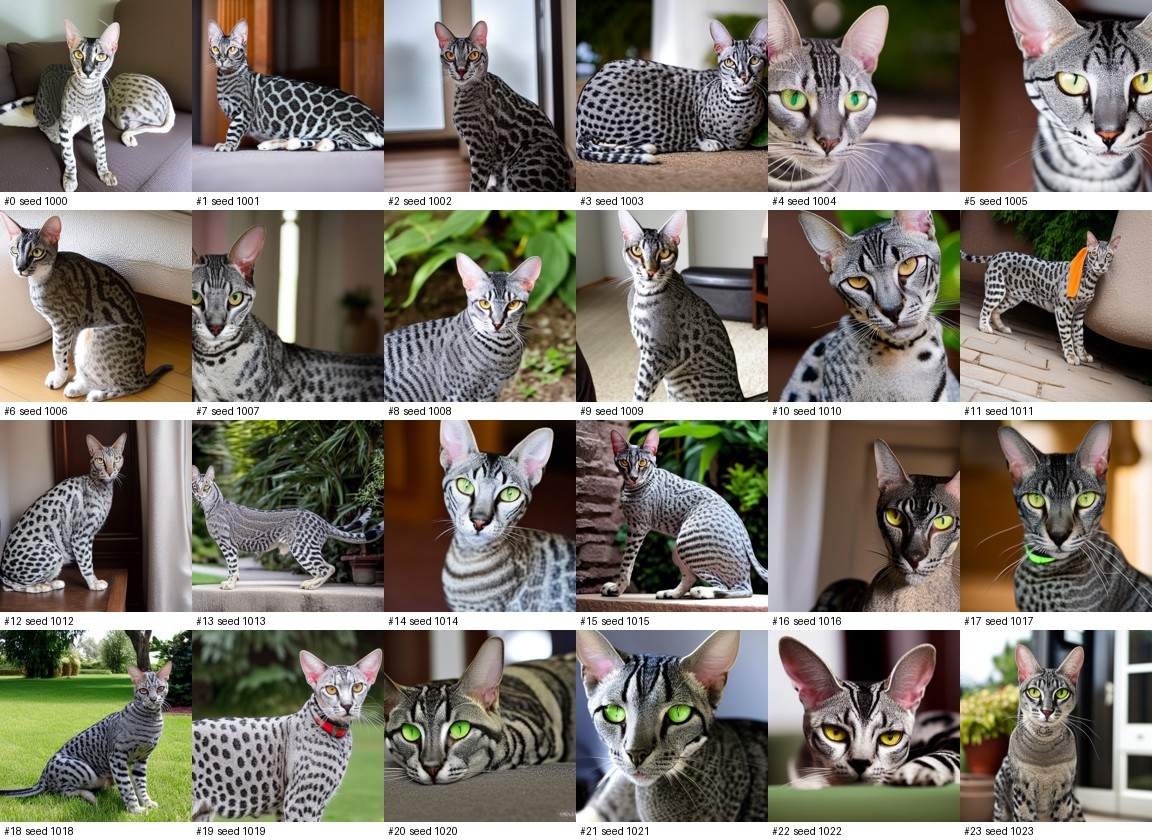

m2-guidance-2


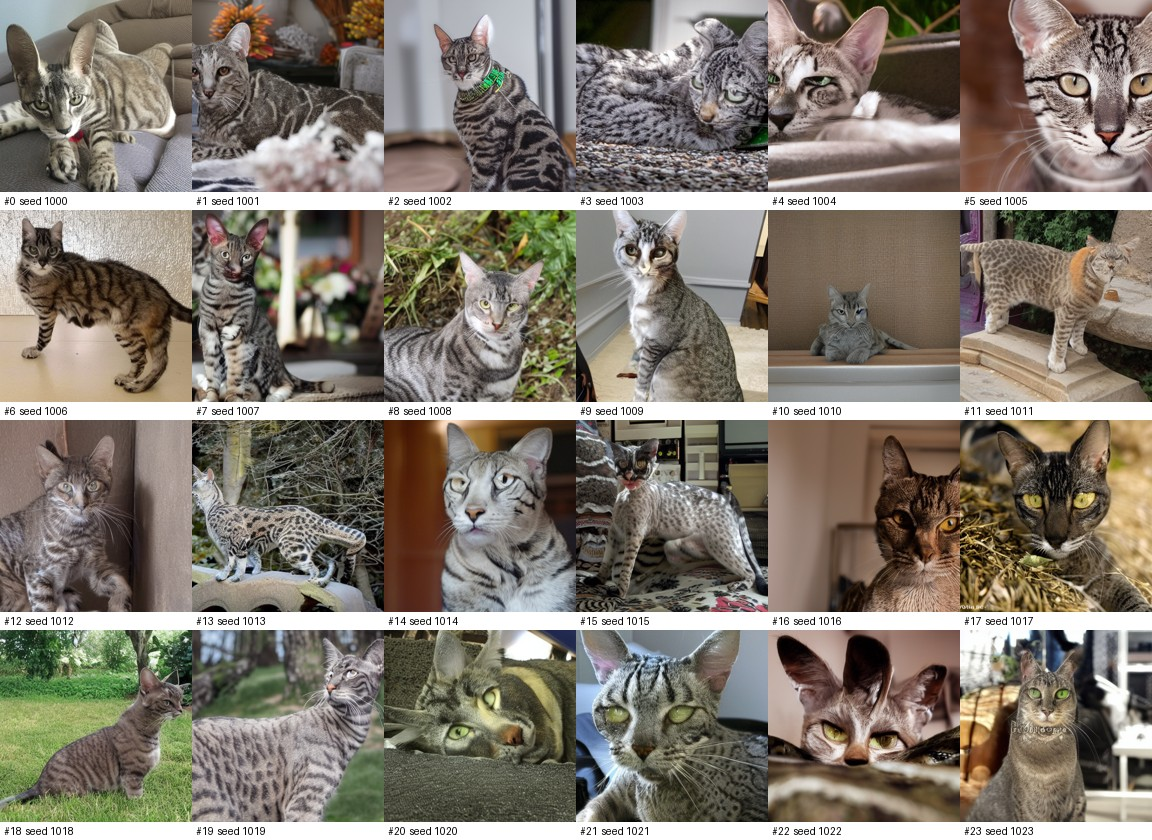

m2-guidance-15


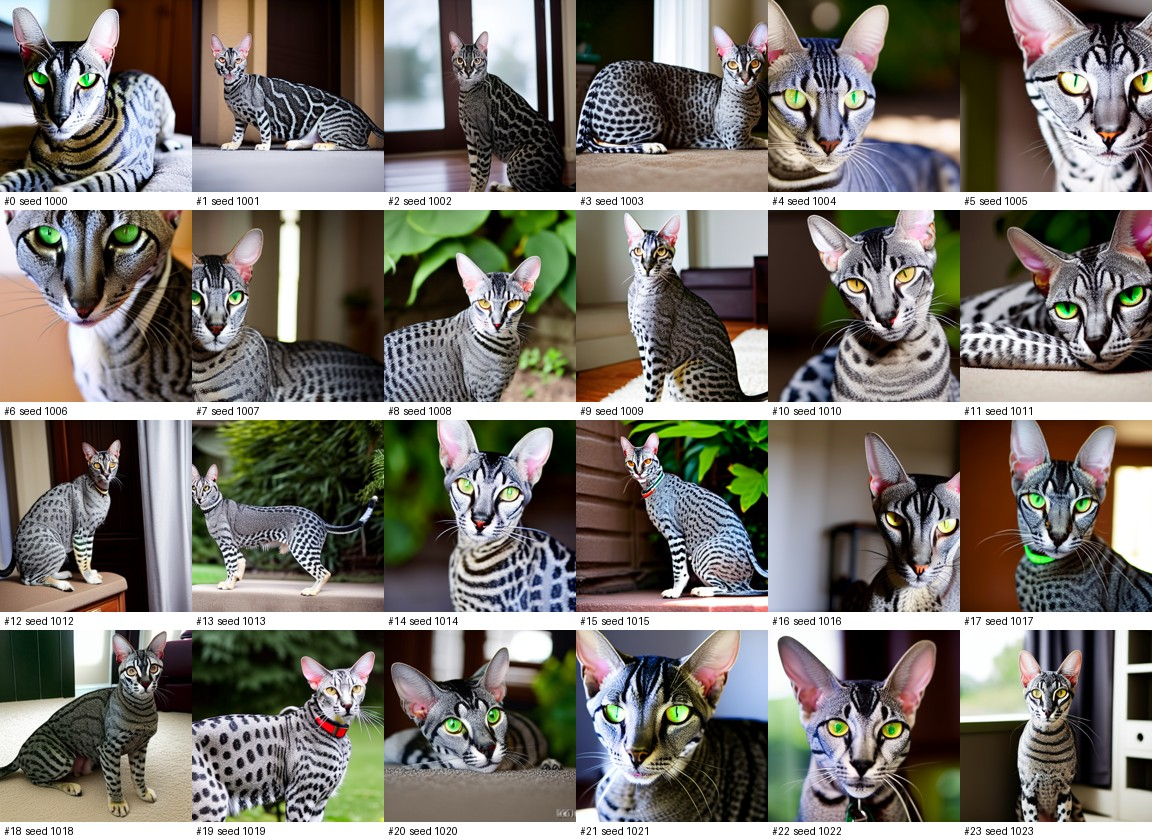

m2-steps-5


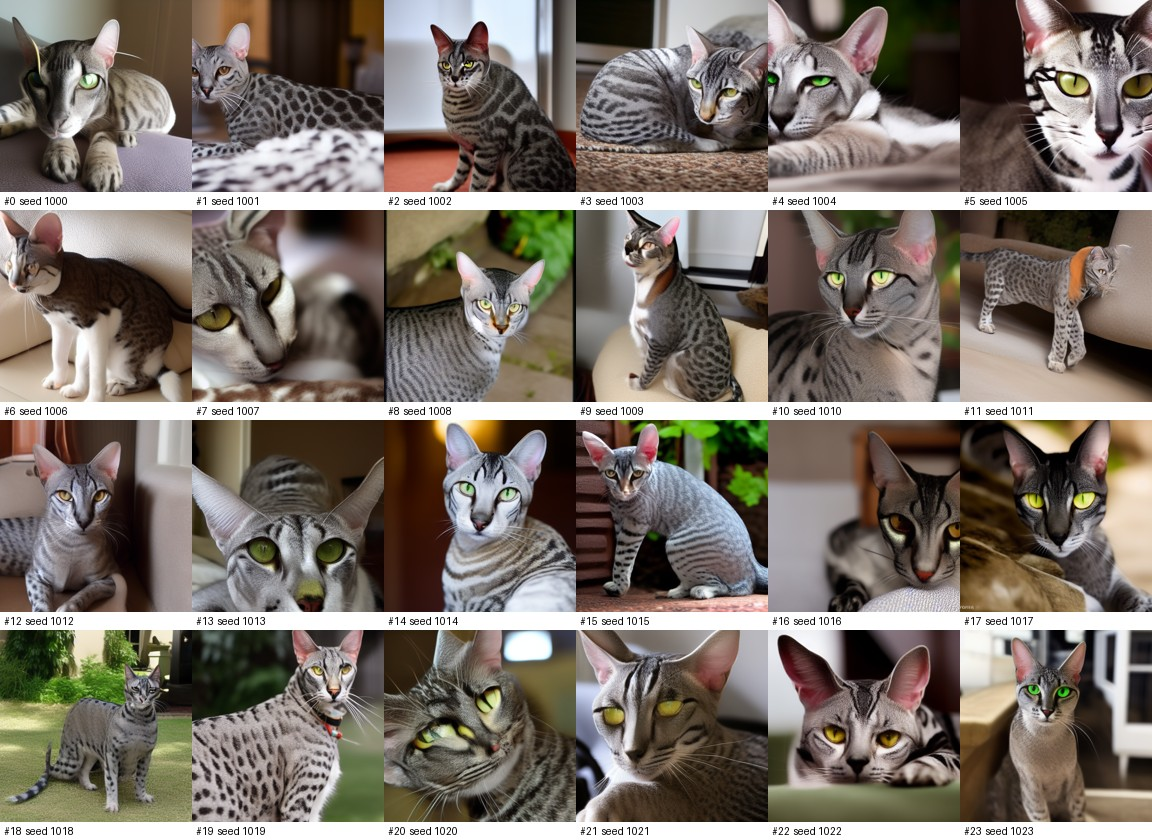

m2-steps-10


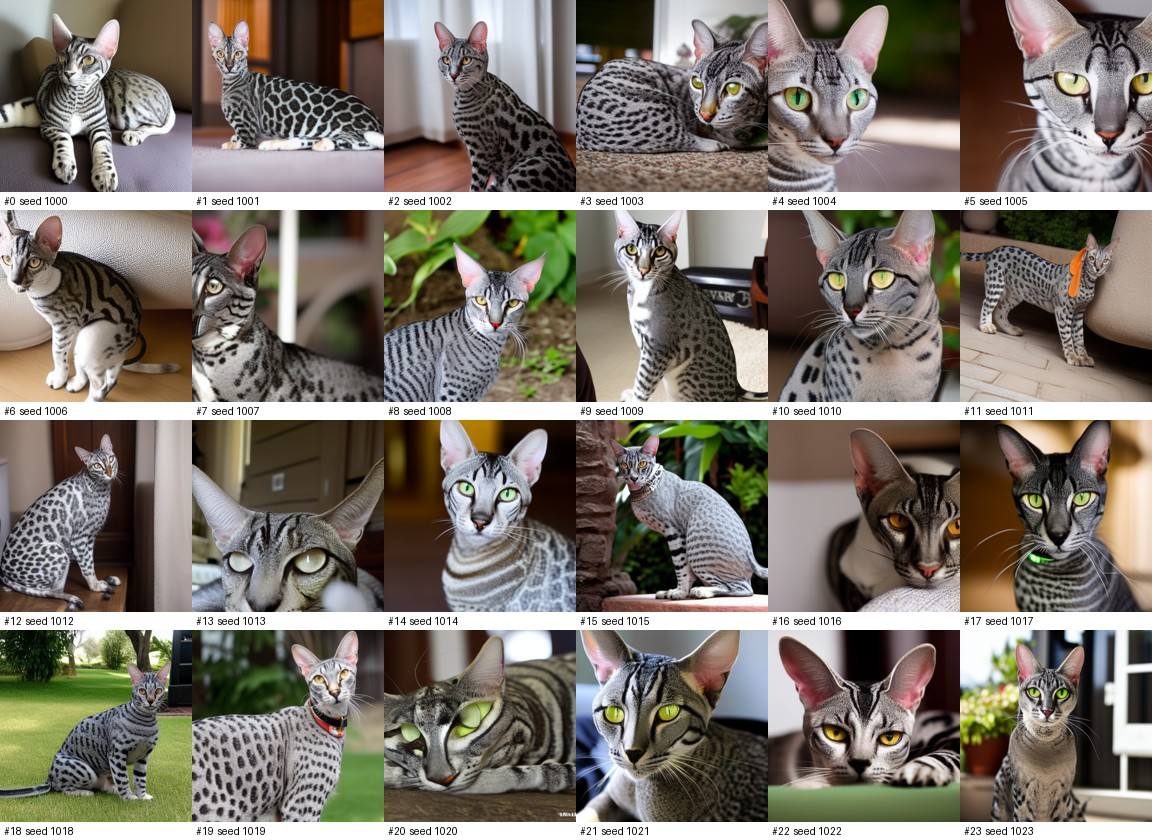

m2-prompts-varied


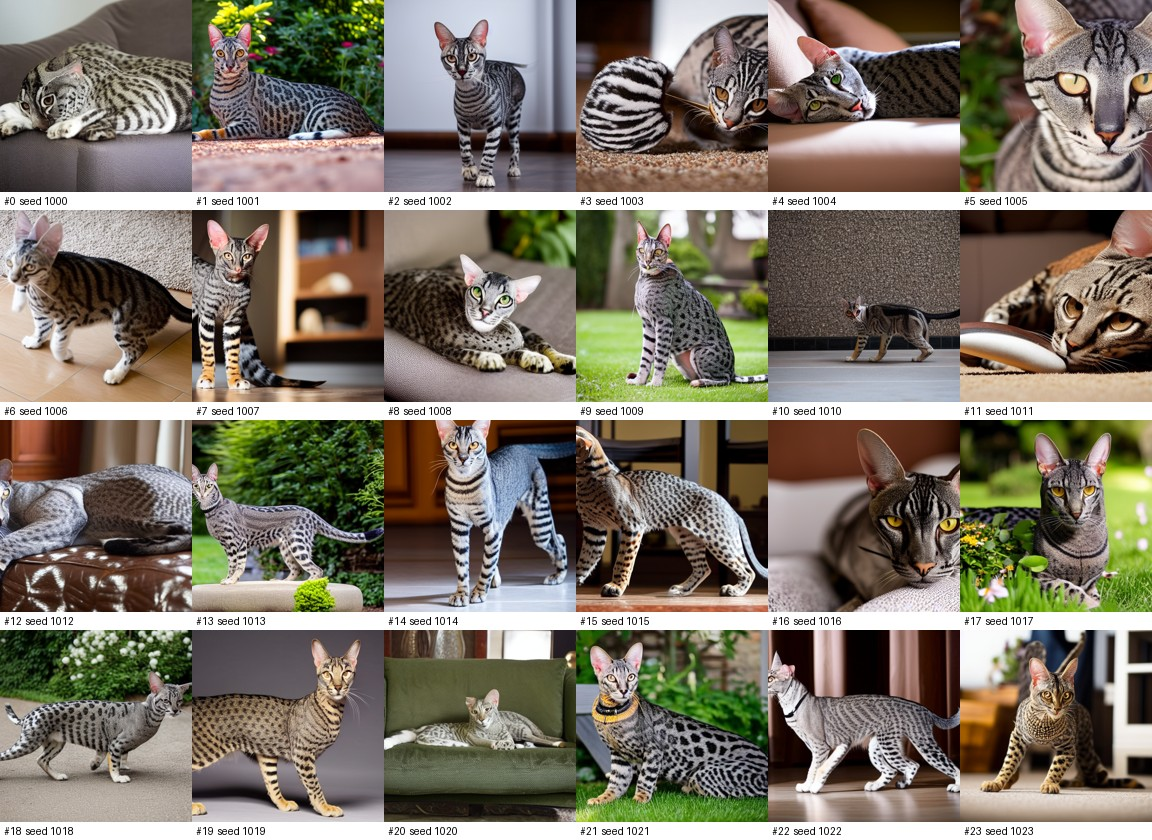

In [4]:
for pool in POOLS:
    print(pool)
    display(ShowImage(filename=str(POOLS_DIR / pool / "contact-sheet.jpg"), width=900))

## 4. Failure types

Looking through the contact sheets, these are the failures that recur (the numbers are image indices on the sheets):

| Failure type | Where | Examples |
|---|---|---|
| **Wrong coat: stripes instead of spots** — a mackerel tabby, not an Egyptian Mau | every pool, about a third of the base sheet | base #5, #7, #8, #14, #20–#22 |
| **Wrong spot pattern** — large blotches or dense leopard / dalmatian spots | base, guidance 15 | base #1, #3, #19 |
| **Impossible anatomy or artefacts** — stretched body, orange blob, two cats merged, cat fused with an object | all pools | base #13, #11; guidance 2 #4; varied #3, #11 |
| **Exaggerated breed features** — huge pink ears, neon-green eyes, thin Oriental-type head | strongest with guidance 15 | guidance 15 #0, #6, #21 |
| **Generic tabby** — a realistic cat that is not recognisably an Egyptian Mau (brown or grey, striped) | guidance 2 | guidance 2 #6, #12, #16, #18 |
| **Text / watermark** | guidance 2 | guidance 2 #17, #23 |
| **Soft, low-detail images** | steps 5 | steps 5 #7, #13, #20 |
| **Repeated framing** — many front-facing head close-ups, always silver, always indoors | base and every single-prompt pool | base #4, #5, #14, #16, #17, #20–#22 |
| **Bengal-like cats** — bronze coats with rosette-like spots | varied prompts | varied #19, #23 |

No painting- or cartoon-style images appeared: the default negative prompt keeps the images photographic.
The figure below collects examples of each type next to convincing images.

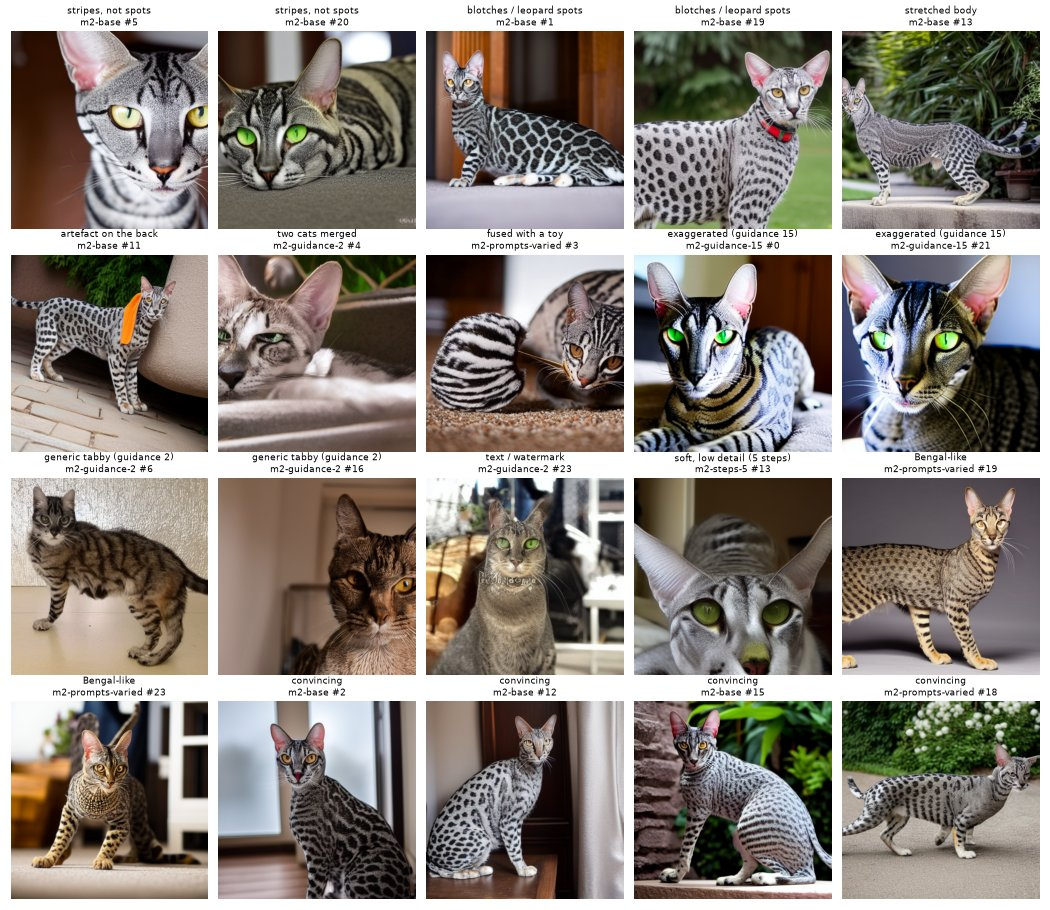

In [5]:
EXAMPLES = [
    ("stripes, not spots", "m2-base", 5), ("stripes, not spots", "m2-base", 20),
    ("blotches / leopard spots", "m2-base", 1), ("blotches / leopard spots", "m2-base", 19),
    ("stretched body", "m2-base", 13), ("artefact on the back", "m2-base", 11),
    ("two cats merged", "m2-guidance-2", 4), ("fused with a toy", "m2-prompts-varied", 3),
    ("exaggerated (guidance 15)", "m2-guidance-15", 0), ("exaggerated (guidance 15)", "m2-guidance-15", 21),
    ("generic tabby (guidance 2)", "m2-guidance-2", 6), ("generic tabby (guidance 2)", "m2-guidance-2", 16),
    ("text / watermark", "m2-guidance-2", 23), ("soft, low detail (5 steps)", "m2-steps-5", 13),
    ("Bengal-like", "m2-prompts-varied", 19), ("Bengal-like", "m2-prompts-varied", 23),
    ("convincing", "m2-base", 2), ("convincing", "m2-base", 12),
    ("convincing", "m2-base", 15), ("convincing", "m2-prompts-varied", 18),
]


def pool_image(pool, index):
    return Image.open(POOLS_DIR / pool / "images" / f"{pool}-{index:04d}.png")


path = EVIDENCE_DIR / "m2-failures.jpg"
if all((POOLS_DIR / p / "images" / f"{p}-{i:04d}.png").exists() for _, p, i in EXAMPLES):
    fig, axes = plt.subplots(4, 5, figsize=(15, 13))
    for ax, (label, pool, index) in zip(axes.flat, EXAMPLES):
        ax.imshow(pool_image(pool, index))
        ax.set_title(f"{label}\n{pool} #{index}", fontsize=9)
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(path, dpi=70, pil_kwargs={"quality": 85})
    plt.close(fig)
# the images are not in Git, so the notebook shows the saved figure
display(ShowImage(filename=str(path), width=1000))

### The same starting noise under every setting

Each column uses the same seed, so every row starts from the same noise; each row is one pool. Steps 10 is almost
identical to the base (the DPM sampler has nearly converged after 10 steps), 5 steps gives a softer version of the same
image, guidance 2 follows the prompt only loosely (a more ordinary-looking cat, often not an Egyptian Mau), guidance 15
exaggerates contrast, eyes and ears, and the varied prompts change pose and scene.

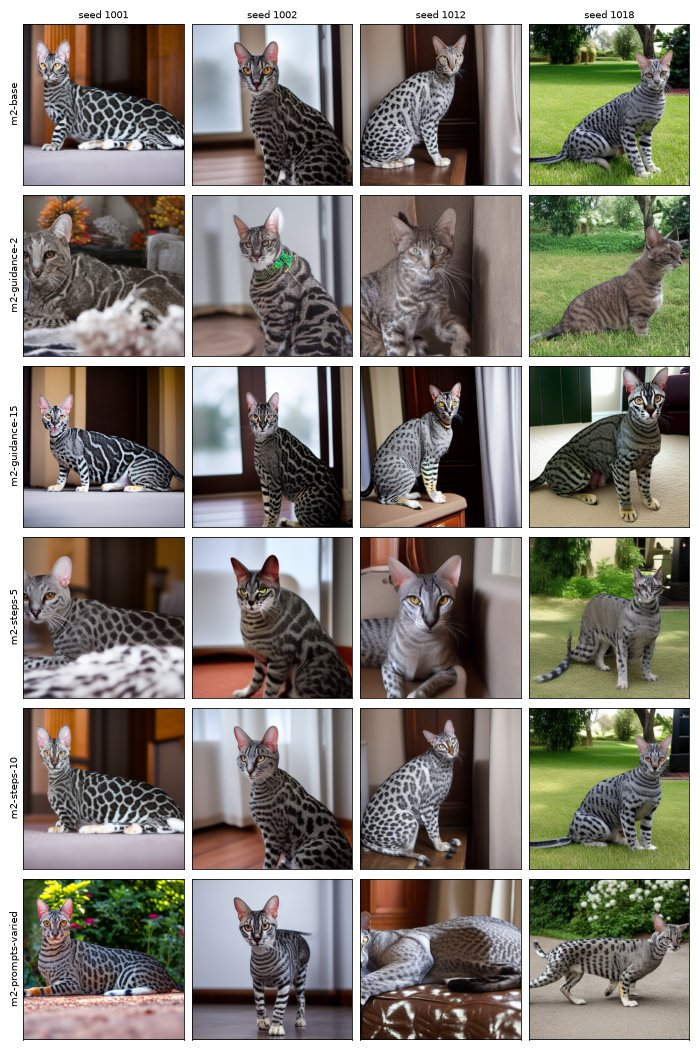

In [6]:
COLUMNS = [1, 2, 12, 18]
path = EVIDENCE_DIR / "m2-same-seeds.jpg"
if all((POOLS_DIR / p / "images" / f"{p}-{i:04d}.png").exists() for p in POOLS for i in COLUMNS):
    fig, axes = plt.subplots(len(POOLS), len(COLUMNS), figsize=(10, 15))
    for r, pool in enumerate(POOLS):
        for c, index in enumerate(COLUMNS):
            ax = axes[r, c]
            ax.imshow(pool_image(pool, index))
            ax.set_xticks([])
            ax.set_yticks([])
            if c == 0:
                ax.set_ylabel(pool, fontsize=10)
            if r == 0:
                ax.set_title(f"seed {1000 + index}", fontsize=10)
    fig.tight_layout()
    fig.savefig(path, dpi=70, pil_kwargs={"quality": 85})
    plt.close(fig)
display(ShowImage(filename=str(path), width=650))

## 5. Training

Every pool is trained with 5 seeds; the tags record the setting values so the comparisons can be plotted from
`results.json`. Finished seeds are skipped.

```bash
uv run synth-train --name m2-base --method synthetic --pool m2-base --tag changed=base --tag guidance=7.5 --tag steps=30 --tag prompt=single
uv run synth-train --name m2-guidance-2 --method synthetic --pool m2-guidance-2 --tag changed=guidance --tag guidance=2 --tag steps=30 --tag prompt=single
uv run synth-train --name m2-guidance-15 --method synthetic --pool m2-guidance-15 --tag changed=guidance --tag guidance=15 --tag steps=30 --tag prompt=single
uv run synth-train --name m2-steps-5 --method synthetic --pool m2-steps-5 --tag changed=steps --tag guidance=7.5 --tag steps=5 --tag prompt=single
uv run synth-train --name m2-steps-10 --method synthetic --pool m2-steps-10 --tag changed=steps --tag guidance=7.5 --tag steps=10 --tag prompt=single
uv run synth-train --name m2-prompts-varied --method synthetic --pool m2-prompts-varied --tag changed=prompt --tag guidance=7.5 --tag steps=30 --tag prompt=varied
```

In [7]:
TAGS = {
    "m2-base": dict(changed="base", guidance=7.5, steps=30, prompt="single"),
    "m2-guidance-2": dict(changed="guidance", guidance=2, steps=30, prompt="single"),
    "m2-guidance-15": dict(changed="guidance", guidance=15, steps=30, prompt="single"),
    "m2-steps-5": dict(changed="steps", guidance=7.5, steps=5, prompt="single"),
    "m2-steps-10": dict(changed="steps", guidance=7.5, steps=10, prompt="single"),
    "m2-prompts-varied": dict(changed="prompt", guidance=7.5, steps=30, prompt="varied"),
}
for pool, tags in TAGS.items():
    tag_args = [arg for key, value in tags.items() for arg in ("--tag", f"{key}={value}")]
    train.main(["--name", pool, "--method", "synthetic", "--pool", pool, *tag_args])

m2-base: synthetic, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m2-base\results.json


m2-guidance-2: synthetic, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m2-guidance-2\results.json


m2-guidance-15: synthetic, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m2-guidance-15\results.json


m2-steps-5: synthetic, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m2-steps-5\results.json


m2-steps-10: synthetic, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m2-steps-10\results.json


m2-prompts-varied: synthetic, efficientnet_b0, 5 seeds, cuda
  seed 0: already done
  seed 1: already done
  seed 2: already done
  seed 3: already done
  seed 4: already done
Results of every seed are in D:\PROJEKTY\STUDIA\Syntetyczne dane (projekt) - synthetic-cats-benchmark\runs\m2-prompts-varied\results.json


## 6. Validation results (every seed)

20 Egyptian Mau validation photos, so one photo = 0.05 recall. The Meeting 1 baselines are included for comparison.

In [8]:
def load_results(runs, filename="results.json"):
    rows = []
    for run in runs:
        data = json.loads((RUNS_DIR / run / filename).read_text())
        for s in data["seeds"]:
            rows.append({"run": run, **data.get("tags", {}), "seed": s["seed"],
                         "egyptian_mau_recall": s["egyptian_mau_recall"], "macro_f1": s["macro_f1"],
                         **{f"recall {b}": s["recall"][b] for b in CLASSES}})
    return pd.DataFrame(rows)


def seed_table(results, runs):
    tables = []
    for metric in ["egyptian_mau_recall", "macro_f1"]:
        wide = results.pivot(index="seed", columns="run", values=metric)[runs]
        wide.loc["mean"] = wide.loc[0:4].mean()
        wide.loc["std"] = wide.loc[0:4].std()
        tables.append(wide.T.add_prefix(f"{metric} | "))
    return pd.concat(tables, axis=1)


RUNS = BASELINES + POOLS
val = load_results(RUNS)
val_table = seed_table(val, RUNS)
val_table.round(3).to_csv(EVIDENCE_DIR / "m2-validation.csv")
val_table.round(3)

seed,egyptian_mau_recall | 0,egyptian_mau_recall | 1,egyptian_mau_recall | 2,egyptian_mau_recall | 3,egyptian_mau_recall | 4,egyptian_mau_recall | mean,egyptian_mau_recall | std,macro_f1 | 0,macro_f1 | 1,macro_f1 | 2,macro_f1 | 3,macro_f1 | 4,macro_f1 | mean,macro_f1 | std
run,,,,,,,,,,,,,,
m1-real,0.45,0.50,0.50,0.40,0.60,0.49,0.074,0.861,0.857,0.869,0.840,0.859,0.857,0.010
m1-oversample,0.65,0.60,0.65,0.75,0.70,0.67,0.057,0.885,0.878,0.885,0.912,0.911,0.894,0.016
m1-augment,0.70,0.70,0.70,0.85,0.70,0.73,0.067,0.886,0.861,0.879,0.905,0.898,0.886,0.017
m2-base,0.80,0.75,0.75,0.85,0.80,0.79,0.042,0.912,0.881,0.899,0.900,0.919,0.902,0.014
m2-guidance-2,0.80,0.80,0.80,0.80,0.85,0.81,0.022,0.905,0.868,0.906,0.874,0.918,0.894,0.022
m2-guidance-15,0.75,0.70,0.75,0.80,0.80,0.76,0.042,0.899,0.869,0.899,0.900,0.906,0.895,0.015
m2-steps-5,0.80,0.80,0.75,0.85,0.80,0.80,0.035,0.912,0.882,0.899,0.900,0.912,0.901,0.012
m2-steps-10,0.80,0.80,0.75,0.85,0.80,0.80,0.035,0.912,0.900,0.899,0.913,0.912,0.907,0.007
m2-prompts-varied,0.75,0.75,0.75,0.90,0.80,0.79,0.065,0.905,0.875,0.899,0.913,0.918,0.902,0.017


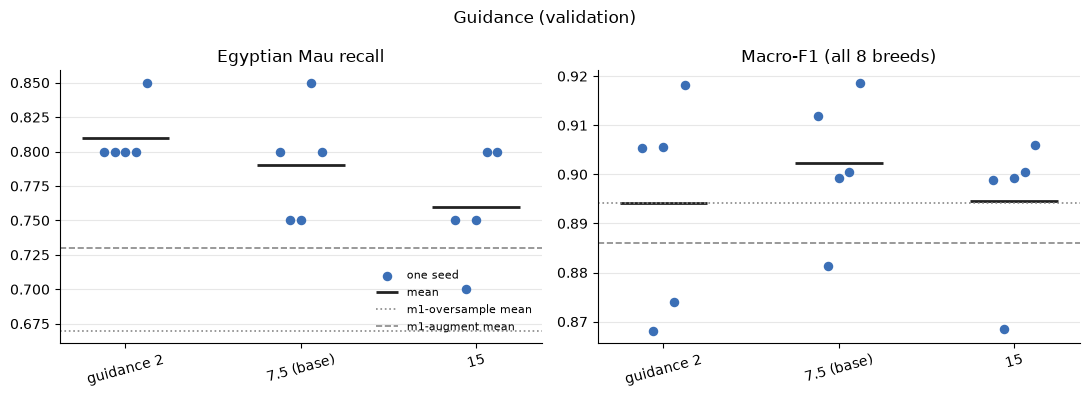

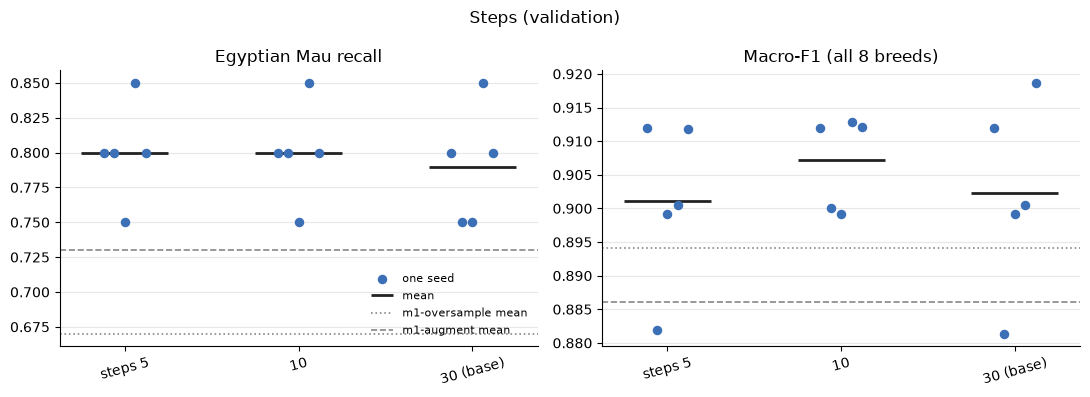

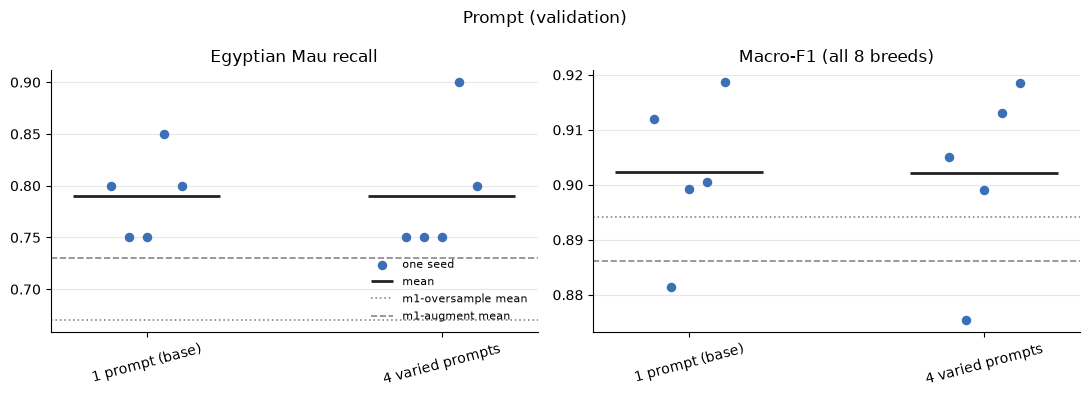

In [9]:
BLUE, GREY = "#3b6fb6", "#888888"
METRICS = [("egyptian_mau_recall", "Egyptian Mau recall"), ("macro_f1", "Macro-F1 (all 8 breeds)")]
baseline_means = val[val.run.isin(BASELINES)].groupby("run")[["egyptian_mau_recall", "macro_f1"]].mean()


def dots(ax, results, runs, metric, labels=None):
    for x, run in enumerate(runs):
        values = results.loc[results.run == run, metric].to_numpy()
        ax.scatter(x + np.linspace(-0.12, 0.12, len(values)), values, s=34, color=BLUE, zorder=3,
                   label="one seed" if x == 0 else None)
        ax.hlines(values.mean(), x - 0.25, x + 0.25, color="#222222", lw=2, zorder=2,
                  label="mean" if x == 0 else None)
    ax.set_xticks(range(len(runs)), labels or runs, rotation=15)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)


def baseline_lines(ax, metric):
    for run, style in [("m1-oversample", ":"), ("m1-augment", "--")]:
        ax.axhline(baseline_means.loc[run, metric], color=GREY, ls=style, lw=1.2, label=f"{run} mean")


def comparison(runs, labels, title, path):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, (metric, label) in zip(axes, METRICS):
        dots(ax, val, runs, metric, labels)
        baseline_lines(ax, metric)
        ax.set_title(label)
    axes[0].legend(frameon=False, fontsize=8, loc="lower right")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=100)
    plt.show()


comparison(["m2-guidance-2", "m2-base", "m2-guidance-15"], ["guidance 2", "7.5 (base)", "15"],
           "Guidance (validation)", EVIDENCE_DIR / "m2-guidance.png")
comparison(["m2-steps-5", "m2-steps-10", "m2-base"], ["steps 5", "10", "30 (base)"],
           "Steps (validation)", EVIDENCE_DIR / "m2-steps.png")
comparison(["m2-base", "m2-prompts-varied"], ["1 prompt (base)", "4 varied prompts"],
           "Prompt (validation)", EVIDENCE_DIR / "m2-prompt.png")

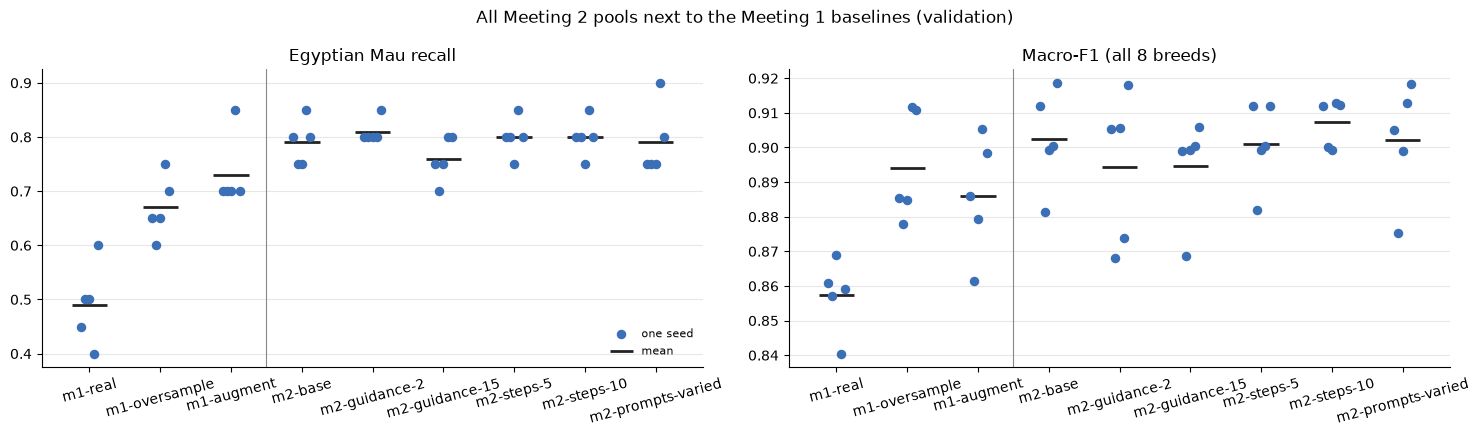

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for ax, (metric, label) in zip(axes, METRICS):
    dots(ax, val, RUNS, metric)
    ax.set_title(label)
    ax.axvline(2.5, color=GREY, lw=0.8)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("All Meeting 2 pools next to the Meeting 1 baselines (validation)")
fig.tight_layout()
fig.savefig(EVIDENCE_DIR / "m2-validation.png", dpi=100)

### Where do the Egyptian Mau mistakes go — and does it cost Bengal?

Summed over the 5 seeds (100 predictions of Egyptian Mau photos per run).

In [11]:
def confusion(run, filename="metrics.json"):
    return sum(np.array(json.loads((RUNS_DIR / run / f"seed-{k}" / filename).read_text())["confusion"])
               for k in range(5))


def mau_mistakes(runs, filename="metrics.json"):
    i, b = CLASSES.index(TARGET), CLASSES.index("Bengal")
    rows = {}
    for run in runs:
        total = confusion(run, filename)
        rows[run] = {**dict(zip(CLASSES, total[i])), "Bengal predicted as Egyptian Mau": total[b, i],
                     "all predictions of Egyptian Mau": total[:, i].sum()}
    table = pd.DataFrame(rows).T
    return table.loc[:, table.sum() > 0]


def breed_recall(results):
    table = results.groupby("run", sort=False)[[f"recall {b}" for b in CLASSES]].mean()
    table.columns = CLASSES
    return table.round(2)


display(mau_mistakes(RUNS))
display(breed_recall(val))

,Abyssinian,Bengal,Egyptian Mau,Ragdoll,Russian Blue,Bengal predicted as Egyptian Mau,all predictions of Egyptian Mau
m1-real,10,26,49,0,15,1,50
m1-oversample,10,12,67,1,10,6,73
m1-augment,10,10,73,0,7,12,85
m2-base,7,10,79,0,4,4,83
m2-guidance-2,5,14,81,0,0,12,93
m2-guidance-15,8,10,76,0,6,5,81
m2-steps-5,6,10,80,0,4,5,85
m2-steps-10,6,10,80,0,4,5,85
m2-prompts-varied,5,9,79,0,7,4,83


,Abyssinian,Bengal,Birman,Bombay,Egyptian Mau,Ragdoll,Russian Blue,Siamese
run,,,,,,,,
m1-real,0.94,0.85,0.87,1.00,0.49,0.86,1.0,0.90
m1-oversample,0.99,0.83,0.92,1.00,0.67,0.85,1.0,0.91
m1-augment,0.97,0.75,0.92,0.98,0.73,0.85,1.0,0.90
m2-base,0.96,0.83,0.89,0.99,0.79,0.86,1.0,0.90
m2-guidance-2,0.95,0.74,0.93,0.97,0.81,0.87,1.0,0.89
m2-guidance-15,0.96,0.83,0.88,0.98,0.76,0.85,1.0,0.90
m2-steps-5,0.96,0.82,0.89,0.98,0.80,0.86,1.0,0.90
m2-steps-10,0.97,0.84,0.89,0.99,0.80,0.86,1.0,0.91
m2-prompts-varied,0.96,0.84,0.90,0.98,0.79,0.85,1.0,0.90


### What the validation results show

* **Every synthetic pool beats both Meeting 1 baselines on average.** Mean Egyptian Mau recall is 0.76–0.81 for the six
  pools, against 0.67 for oversampling and 0.73 for augmentation. Against oversampling this is clear: 29 of the 30
  pool seeds are at or above the best oversampling seed (0.75). Against augmentation the gap is about one validation
  photo and the seed ranges overlap (augmentation 0.70–0.85, pools 0.70–0.90), so it is **not clearly different**.
* **Unlike augmentation, synthetic images mostly do not cost Bengal.** Bengal recall stays at 0.82–0.84 (0.85 without
  added data, 0.75 with augmentation), Bengal photos predicted as Egyptian Mau stay at 4–5 of 100 (12 with
  augmentation), and macro-F1 is as high as or higher than with either fix (0.894–0.907, against 0.894 for
  oversampling and 0.886 for augmentation).
* **The generation settings change the classifier much less than they change the images.** All six pools are within
  0.05 (one validation photo) of each other, and their seed ranges overlap, so no single setting is clearly better:
  * **Guidance:** 2 gives the highest mean (0.81) but is the exception to the point above — Bengal recall drops to 0.74
    and 12 Bengals are called Egyptian Mau. Its images are often generic tabbies, which seems to make the classifier
    call more spotted or striped cats "Egyptian Mau" (93 predictions instead of 81–85). Guidance 15, with its
    exaggerated images, gives the lowest mean (0.76).
  * **Steps:** 5, 10 and 30 give the same recall (0.80, 0.80, 0.79). Steps 10 makes almost the same images as 30; the
    softer 5-step images still work as well — at a quarter of the generation time.
  * **Prompt:** four varied prompts give the same mean recall as one prompt (0.79) and the same macro-F1 (0.902), with
    more varied poses and scenes; the Bengal-like bronze images did not increase the Bengal confusion (4 of 100).

## 7. Choice (made on validation, before testing)

**`m2-prompts-varied` is taken forward.** On validation all six pools are within one photo of each other in Egyptian
Mau recall, so the main metric alone does not decide. `m2-prompts-varied` ties the best pools (0.79 recall, 0.902
macro-F1), has the smallest cost to Bengal (0.84 recall, 4 of 100 Bengal photos called Egyptian Mau), and its contact
sheet is the only one without the "repeated framing" failure. Guidance 2 has the highest mean (0.81), but only by a
third of a photo, reached by calling more Bengals Egyptian Mau and with images that are often generic tabbies, so it is
not chosen. Only `m2-prompts-varied` is tested.

## 8. Test result, compared with the Meeting 1 baselines

```bash
uv run synth-test --run m2-prompts-varied
```

30 Egyptian Mau test photos, so one photo = 0.033. The run is tested only once: if `test-results.json` exists, the cell
just reads it.

In [12]:
CHOSEN = "m2-prompts-varied"
if (RUNS_DIR / CHOSEN / "test-results.json").exists():
    print(f"{CHOSEN}: already tested")
else:
    test.main(["--run", CHOSEN])

TESTED = BASELINES + [CHOSEN]
test_results = load_results(TESTED, "test-results.json")
test_table = seed_table(test_results, TESTED)
test_table.round(3).to_csv(EVIDENCE_DIR / "m2-test.csv")
test_table.round(3)

m2-prompts-varied: already tested


seed,egyptian_mau_recall | 0,egyptian_mau_recall | 1,egyptian_mau_recall | 2,egyptian_mau_recall | 3,egyptian_mau_recall | 4,egyptian_mau_recall | mean,egyptian_mau_recall | std,macro_f1 | 0,macro_f1 | 1,macro_f1 | 2,macro_f1 | 3,macro_f1 | 4,macro_f1 | mean,macro_f1 | std
run,,,,,,,,,,,,,,
m1-real,0.433,0.533,0.500,0.433,0.633,0.507,0.083,0.846,0.858,0.865,0.846,0.868,0.857,0.010
m1-oversample,0.700,0.667,0.733,0.700,0.700,0.700,0.024,0.875,0.877,0.891,0.883,0.874,0.880,0.007
m1-augment,0.733,0.700,0.733,0.733,0.733,0.727,0.015,0.883,0.878,0.882,0.899,0.878,0.884,0.009
m2-prompts-varied,0.733,0.733,0.733,0.700,0.733,0.727,0.015,0.900,0.879,0.891,0.887,0.879,0.887,0.009


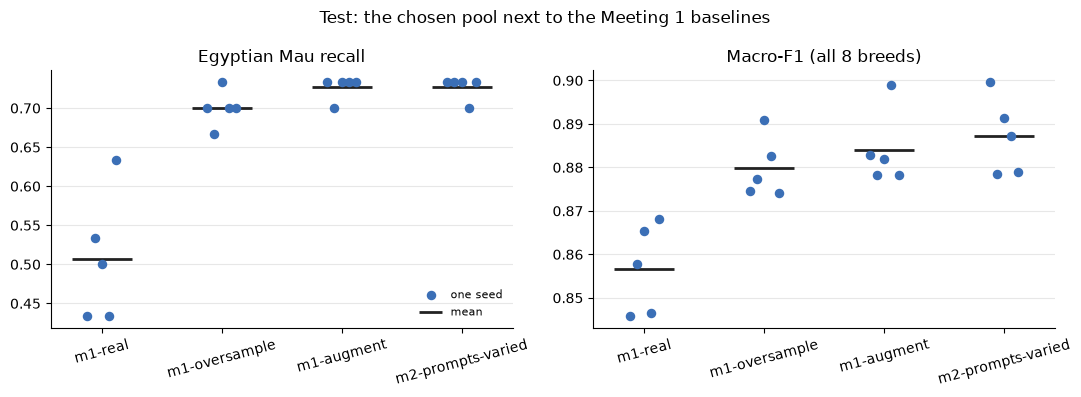

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (metric, label) in zip(axes, METRICS):
    dots(ax, test_results, TESTED, metric)
    ax.set_title(label)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Test: the chosen pool next to the Meeting 1 baselines")
fig.tight_layout()
fig.savefig(EVIDENCE_DIR / "m2-test.png", dpi=100)

In [14]:
means = pd.DataFrame({
    "val Mau recall": val.groupby("run")["egyptian_mau_recall"].mean(),
    "test Mau recall": test_results.groupby("run")["egyptian_mau_recall"].mean(),
    "val macro-F1": val.groupby("run")["macro_f1"].mean(),
    "test macro-F1": test_results.groupby("run")["macro_f1"].mean(),
}).loc[TESTED]
display(means.round(3))
display(mau_mistakes(TESTED, "test-metrics.json"))
display(breed_recall(test_results))

,val Mau recall,test Mau recall,val macro-F1,test macro-F1
run,,,,
m1-real,0.49,0.507,0.857,0.857
m1-oversample,0.67,0.700,0.894,0.880
m1-augment,0.73,0.727,0.886,0.884
m2-prompts-varied,0.79,0.727,0.902,0.887


,Abyssinian,Bengal,Egyptian Mau,Russian Blue,Siamese,Bengal predicted as Egyptian Mau,all predictions of Egyptian Mau
m1-real,4,44,76,26,0,0,76
m1-oversample,6,20,105,18,1,1,106
m1-augment,6,20,109,14,1,7,117
m2-prompts-varied,5,24,109,12,0,0,110


,Abyssinian,Bengal,Birman,Bombay,Egyptian Mau,Ragdoll,Russian Blue,Siamese
run,,,,,,,,
m1-real,0.94,0.93,0.91,0.99,0.51,0.89,0.87,0.87
m1-oversample,0.92,0.90,0.91,0.97,0.70,0.88,0.85,0.91
m1-augment,0.93,0.86,0.91,0.99,0.73,0.88,0.87,0.91
m2-prompts-varied,0.91,0.92,0.91,0.97,0.73,0.90,0.86,0.90


### What the test result shows

* **Egyptian Mau recall:** `m2-prompts-varied` reaches 0.727 (seeds 0.700–0.733, i.e. 21–22 of 30 photos), the same
  mean and range as augmentation (0.727) and 0.027 above oversampling (0.700), less than one test photo. All three are
  clearly above the imbalanced data (0.507). On the test photos the synthetic pool is therefore **not better** than the
  classical fixes in recognising Egyptian Mau.
* **Its validation lead did not hold:** on validation it was 0.06 above augmentation (0.79 vs 0.73); on test the two
  are equal. The validation difference was about one photo, within the seed spread, and the test shows it was not a
  real advantage.
* **Where it does differ: the other breeds.** No Bengal test photo is called Egyptian Mau (augmentation: 7 of 150,
  oversampling: 1), Bengal recall is 0.92 (0.86 with augmentation, 0.93 without added data), and macro-F1 is 0.887
  (0.884 augmentation, 0.880 oversampling) — the same recall for Egyptian Mau, with less harm to Bengal. The Egyptian
  Mau photos it still misses go mostly to Bengal (24) and Russian Blue (12).